In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_csv("airline_passenger_satisfaction_m.csv")

In [3]:
df.head()

,Gender,customer_type,age,type_of_travel,customer_class,flight_distance,inflight_wifi_service,ease_of_online_booking,online_boarding,seat_comfort,inflight_entertainment,onboard_service,leg_room_service,baggage_handling,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction
0,Male,Loyal Customer,18.0,Personal Travel,Eco Plus,545.0,4.0,4.0,4.0,NaN,3.0,NaN,2.0,3.0,2.0,54.0,54.0,satisfied
1,Female,Loyal Customer,NaN,Personal Travel,Business,1063.0,3.0,3.0,2.0,3.0,4.0,4.0,4.0,NaN,2.0,13.0,19.0,neutral or dissatisfied
2,Female,Loyal Customer,47.0,Business travel,Business,1533.0,4.0,3.0,5.0,3.0,5.0,4.0,3.0,5.0,3.0,20.0,12.0,satisfied
3,Male,Loyal Customer,30.0,Business travel,Business,585.0,5.0,5.0,3.0,5.0,5.0,5.0,5.0,5.0,NaN,5.0,5.0,satisfied
4,Male,Loyal Customer,25.0,Business travel,Business,NaN,3.0,2.0,2.0,3.0,2.0,1.0,3.0,3.0,3.0,0.0,5.0,neutral or dissatisfied


In [4]:
df.shape

(8440, 18)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8440 entries, 0 to 8439
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      8016 non-null   object 
 1   customer_type               7960 non-null   object 
 2   age                         7590 non-null   float64
 3   type_of_travel              7830 non-null   object 
 4   customer_class              7944 non-null   object 
 5   flight_distance             7695 non-null   float64
 6   inflight_wifi_service       7391 non-null   float64
 7   ease_of_online_booking      7528 non-null   float64
 8   online_boarding             7590 non-null   float64
 9   seat_comfort                7797 non-null   float64
 10  inflight_entertainment      7393 non-null   float64
 11  onboard_service             7693 non-null   float64
 12  leg_room_service            7632 non-null   float64
 13  baggage_handling            7765 

In [6]:
df.describe()

,age,flight_distance,inflight_wifi_service,ease_of_online_booking,online_boarding,seat_comfort,inflight_entertainment,onboard_service,leg_room_service,baggage_handling,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes
count,7590.000000,7695.000000,7391.000000,7528.000000,7590.000000,7797.000000,7393.000000,7693.000000,7632.000000,7765.000000,7659.000000,7300.000000,7155.000000
mean,39.962582,1568.732424,3.490461,3.482067,3.671146,3.683468,3.667388,3.674119,3.688286,3.856407,3.690560,23.692329,26.120335
std,15.864400,1729.616594,1.057423,1.049434,1.079962,1.060315,1.028879,1.019825,1.096296,0.945371,1.013143,133.794041,142.204939
min,0.000000,50.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,29.000000,627.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,0.000000,0.000000
50%,39.000000,1104.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,4.000000
75%,50.000000,1926.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,14.000000,16.000000
max,120.000000,20000.000000,5.000000,5.000000,10.000000,10.000000,5.000000,5.000000,10.000000,5.000000,5.000000,1800.000000,1800.000000


In [7]:
df["satisfaction"].describe()

count          8440
unique            2
top       satisfied
freq           4580
Name: satisfaction, dtype: object

In [8]:
df.isnull().sum()

Gender                         424
customer_type                  480
age                            850
type_of_travel                 610
customer_class                 496
flight_distance                745
inflight_wifi_service         1049
ease_of_online_booking         912
online_boarding                850
seat_comfort                   643
inflight_entertainment        1047
onboard_service                747
leg_room_service               808
baggage_handling               675
cleanliness                    781
departure_delay_in_minutes    1140
arrival_delay_in_minutes      1285
satisfaction                     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["customer_class"].value_counts()

customer_class
Business    3996
Eco         3021
Eco Plus     927
Name: count, dtype: int64

In [11]:
df["type_of_travel"].value_counts()

type_of_travel
Business travel    5226
Personal Travel    2604
Name: count, dtype: int64

In [12]:
df["customer_type"].value_counts()

customer_type
Loyal Customer       6596
disloyal Customer    1364
Name: count, dtype: int64

In [13]:
df.drop(columns=["Gender","age"], inplace=True)

In [14]:
numeric_cols = ['flight_distance', 'inflight_wifi_service', 'ease_of_online_booking',
       'online_boarding', 'seat_comfort', 'inflight_entertainment',
       'onboard_service', 'leg_room_service', 'baggage_handling',
       'cleanliness', 'departure_delay_in_minutes', 'arrival_delay_in_minutes']

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

In [15]:
df.columns

Index(['customer_type', 'type_of_travel', 'customer_class', 'flight_distance',
       'inflight_wifi_service', 'ease_of_online_booking', 'online_boarding',
       'seat_comfort', 'inflight_entertainment', 'onboard_service',
       'leg_room_service', 'baggage_handling', 'cleanliness',
       'departure_delay_in_minutes', 'arrival_delay_in_minutes',
       'satisfaction'],
      dtype='object')

In [16]:
cat_cols = ["customer_type", "type_of_travel", "customer_class"]

for col in cat_cols:
    df[col] = df[col].fillna("Unknown")

In [17]:
df.isnull().sum()

customer_type                 0
type_of_travel                0
customer_class                0
flight_distance               0
inflight_wifi_service         0
ease_of_online_booking        0
online_boarding               0
seat_comfort                  0
inflight_entertainment        0
onboard_service               0
leg_room_service              0
baggage_handling              0
cleanliness                   0
departure_delay_in_minutes    0
arrival_delay_in_minutes      0
satisfaction                  0
dtype: int64

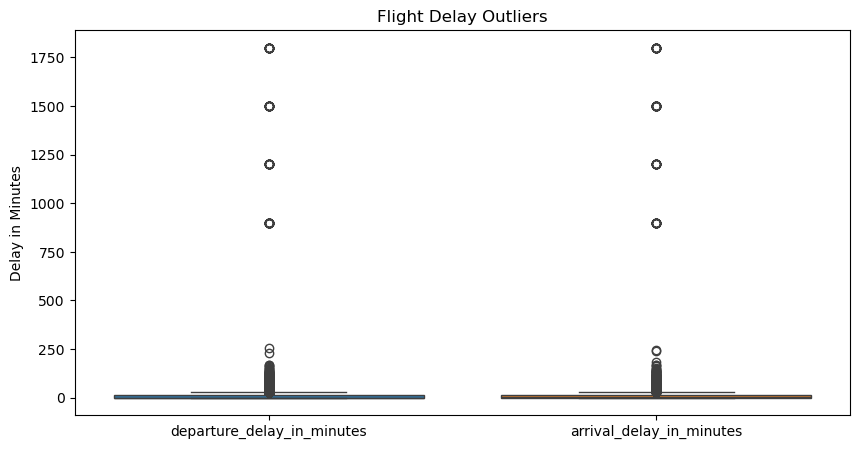

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df[["departure_delay_in_minutes", "arrival_delay_in_minutes"]])

plt.title("Flight Delay Outliers")
plt.ylabel("Delay in Minutes")
plt.show()

In [19]:
cols = [
    "departure_delay_in_minutes",
    "arrival_delay_in_minutes",
    "flight_distance"
]
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col)
    print("IQR:", IQR)
    print("Lower:", lower)
    print("Upper:", upper)
    print("Outliers:", len(outliers))
  

departure_delay_in_minutes
IQR: 11.0
Lower: -16.5
Upper: 27.5
Outliers: 1100
arrival_delay_in_minutes
IQR: 12.0
Lower: -18.0
Upper: 30.0
Outliers: 995
flight_distance
IQR: 1158.25
Lower: -1071.625
Upper: 3561.375
Outliers: 624


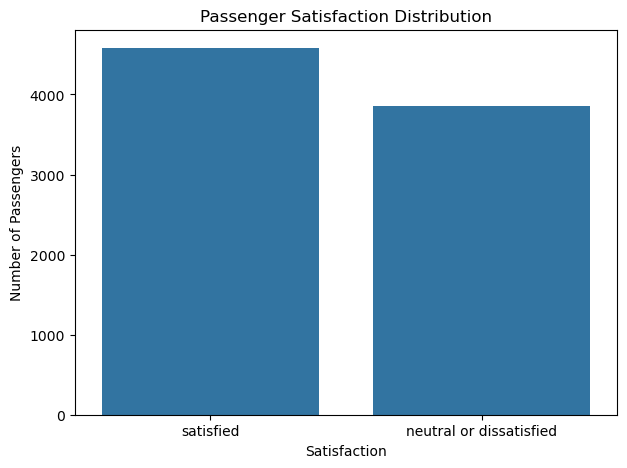

In [20]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="satisfaction")

plt.title("Passenger Satisfaction Distribution")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")

plt.show()

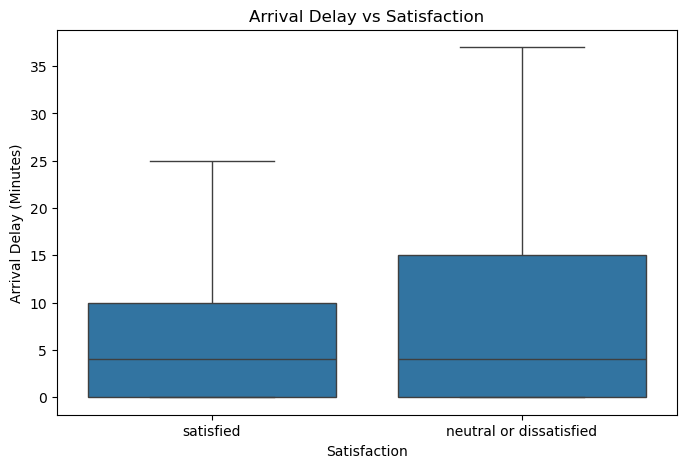

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot( data=df,x="satisfaction", y="arrival_delay_in_minutes", showfliers=False)

plt.title("Arrival Delay vs Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Arrival Delay (Minutes)")

plt.show()

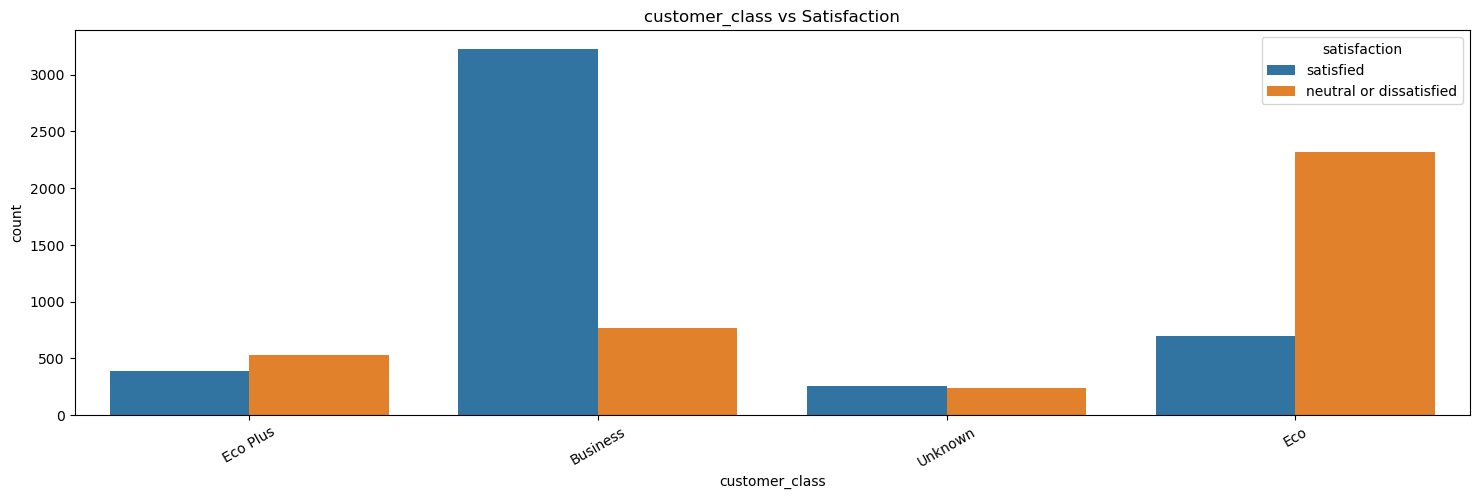

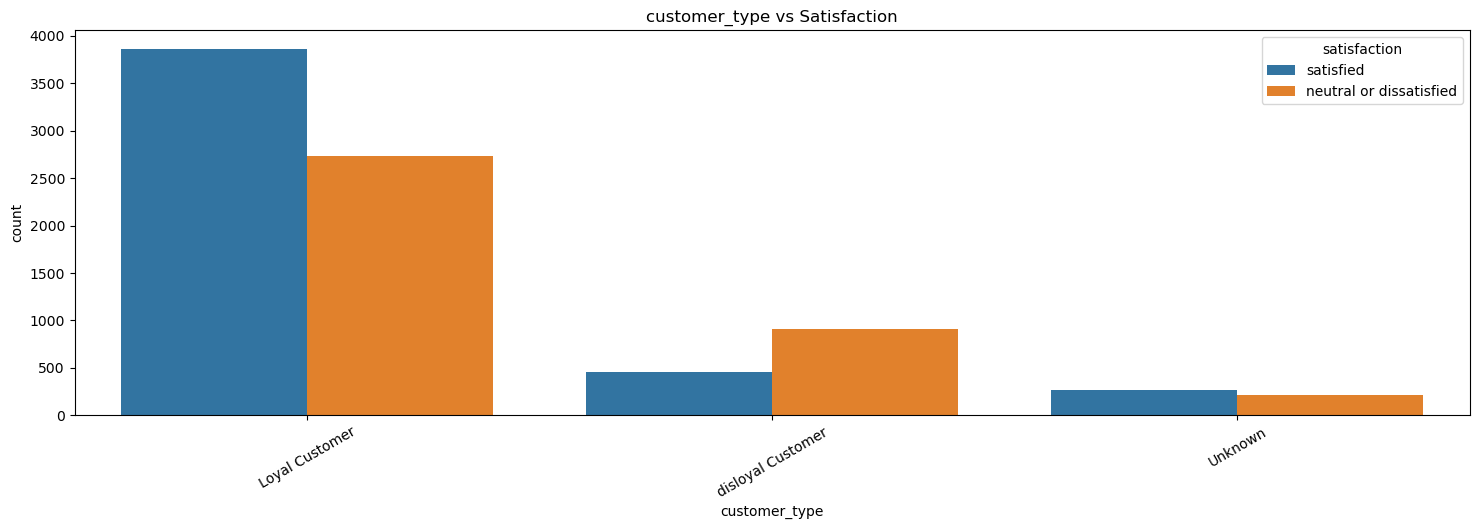

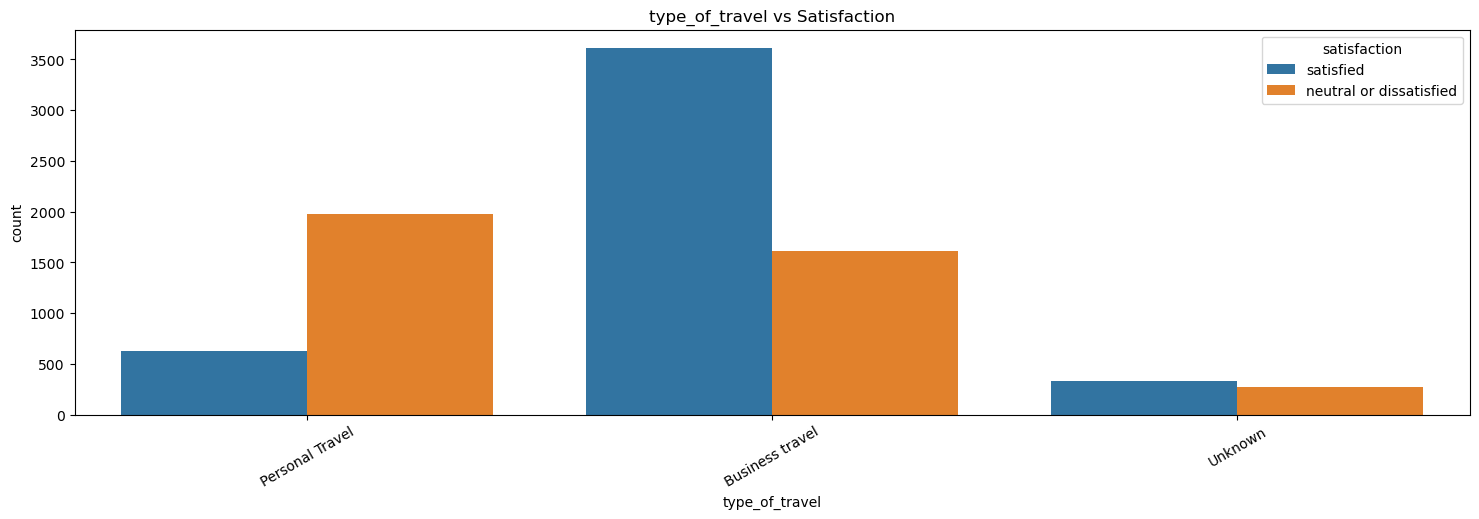

In [22]:
cols = ["customer_class","customer_type","type_of_travel"]

for col in cols:
    plt.figure(figsize=(18, 5))
    sns.countplot(data=df, x=col, hue="satisfaction")
    plt.title(f"{col} vs Satisfaction")
    plt.xticks(rotation=30)
    plt.show()

In [23]:
target = (df["satisfaction"] == "satisfied").astype(int)

numeric_cols = df.select_dtypes(include="number")

correlations = numeric_cols.corrwith(target)

correlations.sort_values(ascending=False)

inflight_entertainment        0.432272
online_boarding               0.412509
baggage_handling              0.409876
onboard_service               0.398937
ease_of_online_booking        0.388682
leg_room_service              0.382043
cleanliness                   0.371291
seat_comfort                  0.367566
inflight_wifi_service         0.351341
flight_distance               0.087924
departure_delay_in_minutes   -0.005082
arrival_delay_in_minutes     -0.005551
dtype: float64

In [24]:
df = pd.get_dummies(df,columns=["customer_type", "type_of_travel", "customer_class"], dtype=int,drop_first=True)

In [25]:
df["satisfaction"] = df["satisfaction"].map({ "satisfied": 1, "neutral or dissatisfied": 0})

In [26]:
df.head()

,flight_distance,inflight_wifi_service,ease_of_online_booking,online_boarding,seat_comfort,inflight_entertainment,onboard_service,leg_room_service,baggage_handling,cleanliness,departure_delay_in_minutes,arrival_delay_in_minutes,satisfaction,customer_type_Unknown,customer_type_disloyal Customer,type_of_travel_Personal Travel,type_of_travel_Unknown,customer_class_Eco,customer_class_Eco Plus,customer_class_Unknown
0,545.0,4.0,4.0,4.0,4.0,3.0,4.0,2.0,3.0,2.0,54.0,54.0,1,0,0,1,0,0,1,0
1,1063.0,3.0,3.0,2.0,3.0,4.0,4.0,4.0,4.0,2.0,13.0,19.0,0,0,0,1,0,0,0,0
2,1533.0,4.0,3.0,5.0,3.0,5.0,4.0,3.0,5.0,3.0,20.0,12.0,1,0,0,0,0,0,0,0
3,585.0,5.0,5.0,3.0,5.0,5.0,5.0,5.0,5.0,4.0,5.0,5.0,1,0,0,0,0,0,0,0
4,1104.0,3.0,2.0,2.0,3.0,2.0,1.0,3.0,3.0,3.0,0.0,5.0,0,0,0,0,0,0,0,0


In [27]:
X = df.drop(columns=[ "satisfaction", "flight_distance","departure_delay_in_minutes","arrival_delay_in_minutes"])

y = df["satisfaction"]

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [31]:
y_pred = model.predict(X_test_scaled)


In [32]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[610 155]
 [119 804]]


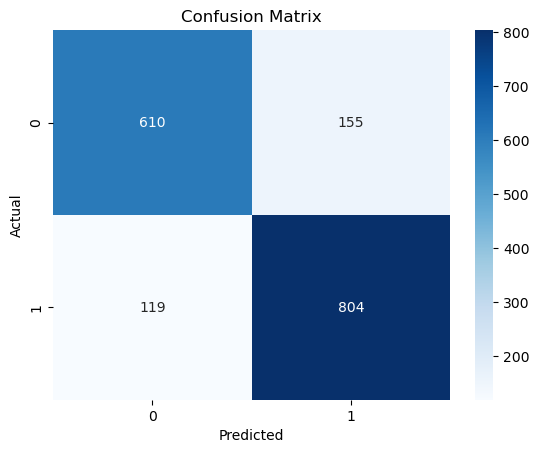

In [33]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [34]:
from sklearn.metrics import recall_score
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

Recall: 0.8710725893824486


In [35]:
from sklearn.metrics import precision_score
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

Precision: 0.8383733055265902


In [36]:
from sklearn.metrics import f1_score
f1 = f1_score(y_test, y_pred)
print("F1 Score:", f1)

F1 Score: 0.8544102019128587


In [37]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8376777251184834
